# B1 — Detecting Fraudulent Job Postings

**Course:** AI-101 Introduction to Artificial Intelligence, Fall 2026
**Student:** Manaal Pervaiz — Roll No. 70173809 — Section BSES A
**Repository:** https://github.com/manaal6/AI101-ML-Assignment-70173809
**Pool / task:** Pool B, Task B1 — supervised binary classification, severe imbalance
**Primary metrics:** F1 on the fraud class, PR-AUC

**How to run:** put `fake_job_postings.csv` in `data/` (see `data/README.md`),
then Kernel → Restart & Run All. The notebook fixes the seed at 42, writes
figures to `figures/` and metric tables to `results/`.

The notebook follows the report's mandatory headings: Introduction, Problem
Statement, Dataset Used, Dataset Statistics, Methodology, Results and Analysis,
Conclusion, References.

## 1. Introduction

Job advertisements are posted at scale on global boards, and a small fraction of
them are fraudulent: they promise non-existent jobs, harvest personal data, or
ask candidates for fees. Because a single posting reaches many applicants, even
a 5 % fraud rate causes real harm, and a platform must triage postings
automatically.

Each posting mixes **structured metadata** (employment type, required
experience, education, industry, function, country, and binary flags such as
whether the company has a logo) with **free text** (title, company profile,
description, requirements, benefits). Either source may be predictive: a missing
company profile is suspicious, and phrases such as "no experience needed" or
"work from home" recur in scams.

The classes are severely imbalanced: 866 of 17,880 postings (4.84 %) are
fraudulent. Accuracy is therefore uninformative — predicting "real" for every
posting scores about 95 %. We build a leakage-free pipeline
(`ColumnTransformer` + TF-IDF), compare Logistic Regression, a Linear SVM and
LightGBM, choose each model's decision threshold on a validation split, and run
the mandatory structured-only / text-only / combined ablation. The measured
result is summarised in Section 6.2.

## 2. Problem Statement

Given one posting $x = (x_{\text{struct}}, x_{\text{text}})$, where
$x_{\text{struct}}$ contains 16 structured attributes and $x_{\text{text}}$ is
the concatenation of five free-text fields, learn $f: x \mapsto y$ with
$y \in \{0,1\}$, where $y=1$ means **fraudulent**.

The task is supervised binary classification with severe class imbalance
(4.84 % positive). Success is measured by **F1 on the fraud class** and
**PR-AUC**, with ROC-AUC reported for completeness. The operating constraint is
that fraud is rare: a model may reach high accuracy by ignoring it, so every
decision threshold is chosen on a validation split and the test set is used only
for the final report.

## 3. Dataset Used

**Name:** Real or Fake Job Posting Prediction (EMSCAD)
**Source:** Kaggle, `shivamb/real-or-fake-fake-jobposting-prediction`
(https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction)
**Licence:** CC0: Public Domain (verified through the Kaggle API)
**Citation:** S. Bhardwaj, "Real or Fake Job Posting Prediction," Kaggle, 2020.
The underlying corpus is EMSCAD (Employment Scam Aegean Dataset), University of
the Aegean.

The CSV has 17,880 rows and 18 columns: `job_id` (identifier, dropped), the
target `fraudulent`, 5 free-text fields (`title`, `company_profile`,
`description`, `requirements`, `benefits`), 3 binary flags (`telecommuting`,
`has_company_logo`, `has_questions`) and 8 metadata columns (`location`,
`department`, `salary_range`, `employment_type`, `required_experience`,
`required_education`, `industry`, `function`).

**Cleaning and feature construction (no rows removed):**

- `job_id` is dropped as an identifier.
- The five text fields are HTML-unescaped, lower-cased, stripped of HTML tags,
  URLs, e-mail addresses, punctuation and digits, then concatenated into one
  `text` field for TF-IDF.
- `country` is derived from the first token of `location` (e.g. `US, NY, New
  York` → `US`); `location` itself is too high-cardinality (3,105 values) to
  one-hot encode.
- Missingness is preserved as signal: `is_missing_company_profile`,
  `is_missing_requirements`, `is_missing_benefits`, plus `salary_present`.
- `department` is dropped: 64.6 % missing and 1,337 values, with no reliable
  recovery rule.
- Rows with empty text are kept; TF-IDF simply gives them a zero vector.

No rows are deleted, so the class counts in Table 1 are the original ones.

In [1]:
from pathlib import Path
import os, sys, json, re, html, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm as lgb

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "font.size": 9,
                     "axes.titlesize": 10, "axes.labelsize": 9})
pd.set_option("display.width", 175); pd.set_option("display.max_columns", 40)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
DATA = Path("data/fake_job_postings.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "data/fake_job_postings.csv not found. Run the Kaggle download command "
        "in B1_Fake_Job_Postings/data/README.md first.")

print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__, "| pandas", pd.__version__)
print("sklearn ", sklearn.__version__, "| lightgbm", lgb.__version__)
print("seed    ", SEED)

python   3.11.9
numpy    1.26.4 | pandas 2.2.3
sklearn  1.5.2 | lightgbm 4.5.0
seed     42


In [2]:
raw = pd.read_csv(DATA)
print("raw shape:", raw.shape)
print("\ncolumns and dtypes")
print(raw.dtypes.to_string())
print("\ntarget counts")
print(raw["fraudulent"].value_counts().rename({0: "real (0)", 1: "fraud (1)"}).to_string())
print(f"fraud rate: {raw['fraudulent'].mean()*100:.2f}%")
print("\nfull-row duplicates:", int(raw.duplicated().sum()))
print("unique job_id:", raw["job_id"].nunique(), "of", len(raw))
print("\nmissing values (%)")
missing = (raw.isna().mean() * 100).sort_values(ascending=False).round(2)
print(missing.to_string())
print("\ntext fields — description characters")
print(raw["description"].fillna("").str.len().describe().round(1).to_string())

raw shape: (17880, 18)

columns and dtypes
job_id                  int64
title                  object
location               object
department             object
salary_range           object
company_profile        object
description            object
requirements           object
benefits               object
telecommuting           int64
has_company_logo        int64
has_questions           int64
employment_type        object
required_experience    object
required_education     object
industry               object
function               object
fraudulent              int64

target counts
fraudulent
real (0)     17014
fraud (1)      866
fraud rate: 4.84%

full-row duplicates: 0
unique job_id: 17880 of 17880

missing values (%)
salary_range           83.96
department             64.58
required_education     45.33
benefits               40.34
required_experience    39.43
function               36.10
industry               27.42
employment_type        19.41
company_profile        18.50


## 4. Dataset Statistics

### 4.1 Feature construction and summary table

The engineered frame has 16 structured columns plus one `text` column. The table
below is generated from the loaded data; the split sizes appear in Section 5.2
because the split is a methodological choice.

In [3]:
TEXT_FIELDS = ["title", "company_profile", "description", "requirements", "benefits"]
NUM_FEATURES = ["text_len", "word_count", "n_text_fields", "salary_present",
                "is_missing_company_profile", "is_missing_requirements",
                "is_missing_benefits"]
BIN_FEATURES = ["telecommuting", "has_company_logo", "has_questions"]
CAT_FEATURES = ["employment_type", "required_experience", "required_education",
                "industry", "function", "country"]
TEXT_FEATURE = "text"


def clean_text(s):
    s = html.unescape(str(s)).lower()
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"\S+@\S+", " ", s)
    s = re.sub(r"[^a-z\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def build_frame(frame):
    out = pd.DataFrame(index=frame.index)
    for c in BIN_FEATURES:
        out[c] = frame[c].astype(int)
    for c in ["employment_type", "required_experience", "required_education",
              "industry", "function"]:
        out[c] = frame[c].fillna("Missing").astype(str)
    out["country"] = (frame["location"].fillna("").str.split(",").str[0]
                      .str.strip().replace("", "Missing"))
    out["text_len"] = frame["description"].fillna("").str.len()
    out["word_count"] = frame["description"].fillna("").str.split().str.len()
    out["n_text_fields"] = frame[TEXT_FIELDS].notna().sum(axis=1)
    out["is_missing_company_profile"] = frame["company_profile"].isna().astype(int)
    out["is_missing_requirements"] = frame["requirements"].isna().astype(int)
    out["is_missing_benefits"] = frame["benefits"].isna().astype(int)
    out["salary_present"] = frame["salary_range"].notna().astype(int)
    out["text"] = (frame["title"].fillna("") + " " +
                   frame["company_profile"].fillna("") + " " +
                   frame["description"].fillna("") + " " +
                   frame["requirements"].fillna("") + " " +
                   frame["benefits"].fillna("")).map(clean_text)
    return out


X = build_frame(raw)
y = raw["fraudulent"].astype(int)

print("engineered frame:", X.shape, "| target:", y.shape)
print("structured columns:", len(NUM_FEATURES) + len(BIN_FEATURES) + len(CAT_FEATURES))
print("  numeric:", NUM_FEATURES)
print("  binary :", BIN_FEATURES)
print("  categorical:", CAT_FEATURES)
print("  text: 1 concatenated field")
print("total columns:", X.shape[1])
print("\nclass counts:", y.value_counts().to_dict())
print("empty text rows after cleaning:", int((X["text"].str.len() == 0).sum()))

engineered frame: (17880, 17) | target: (17880,)
structured columns: 16
  numeric: ['text_len', 'word_count', 'n_text_fields', 'salary_present', 'is_missing_company_profile', 'is_missing_requirements', 'is_missing_benefits']
  binary : ['telecommuting', 'has_company_logo', 'has_questions']
  categorical: ['employment_type', 'required_experience', 'required_education', 'industry', 'function', 'country']
  text: 1 concatenated field
total columns: 17

class counts: {0: 17014, 1: 866}
empty text rows after cleaning: 0


In [4]:
summary_rows = [
    ("Samples", f"{len(raw):,}"),
    ("Raw columns", f"{raw.shape[1]} (1 id, 1 target, 16 inputs)"),
    ("Structured features used", "16 (7 numeric, 3 binary, 6 categorical)"),
    ("Text features", "1 concatenated field -> TF-IDF, max 20,000 1-2-grams"),
    ("Fraudulent (positive)", f"{int(y.sum()):,} ({y.mean()*100:.2f}%)"),
    ("Real", f"{int((1-y).sum()):,} ({(1-y).mean()*100:.2f}%)"),
    ("Majority-class accuracy", f"{(1-y).mean()*100:.2f}%"),
    ("Missing values", "present, used as signal (see Figure 1)"),
    ("Description length (chars)", f"mean {X['text_len'].mean():.0f}, median {X['text_len'].median():.0f}"),
    ("Description length (words)", f"mean {X['word_count'].mean():.0f}, median {X['word_count'].median():.0f}"),
    ("Top derived countries", ", ".join(X['country'].value_counts().head(4).index)),
    ("Duplicate rows", f"{int(raw.duplicated().sum())}"),
]
print("Table 1 — dataset statistics")
print("-" * 78)
for k, v in summary_rows:
    print(f"{k:<34}{v}")

Table 1 — dataset statistics
------------------------------------------------------------------------------
Samples                           17,880
Raw columns                       18 (1 id, 1 target, 16 inputs)
Structured features used          16 (7 numeric, 3 binary, 6 categorical)
Text features                     1 concatenated field -> TF-IDF, max 20,000 1-2-grams
Fraudulent (positive)             866 (4.84%)
Real                              17,014 (95.16%)
Majority-class accuracy           95.16%
Missing values                    present, used as signal (see Figure 1)
Description length (chars)        mean 1218, median 1017
Description length (words)        mean 170, median 146
Top derived countries             US, GB, GR, CA
Duplicate rows                    0


### 4.2 Missingness, class balance and text length (required EDA)

Three facts drive the modelling: which columns are mostly missing, how the
classes differ in text length, and how strongly two simple flags separate the
classes.

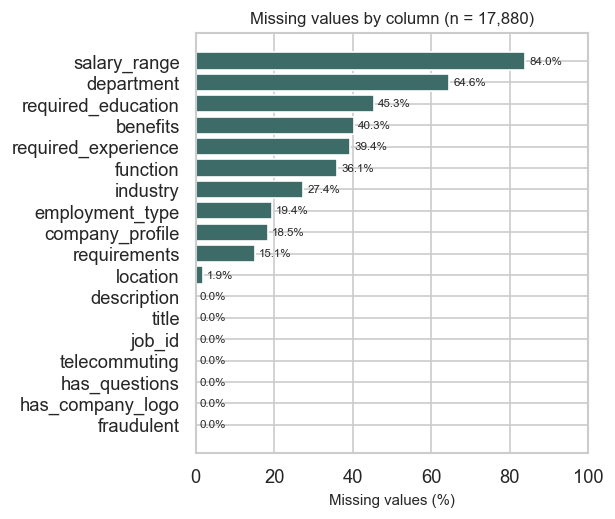

saved figures/fig1_missing_values.png
company_profile missing in 18.50% of rows; salary_range in 83.96%.


In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
miss_sorted = missing.sort_values()
bars = ax.barh(miss_sorted.index, miss_sorted.values, color="#3D6B68")
for b, v in zip(bars, miss_sorted.values):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=7)
ax.set_xlabel("Missing values (%)")
ax.set_title("Missing values by column (n = 17,880)")
ax.set_xlim(0, 100)
fig.tight_layout()
fig.savefig(FIG / "fig1_missing_values.png", bbox_inches="tight")
plt.show()
missing.round(2).to_csv(RES / "b1_missing_values.csv")
print("saved figures/fig1_missing_values.png")
print(f"company_profile missing in {missing['company_profile']:.2f}% of rows; "
      f"salary_range in {missing['salary_range']:.2f}%.")

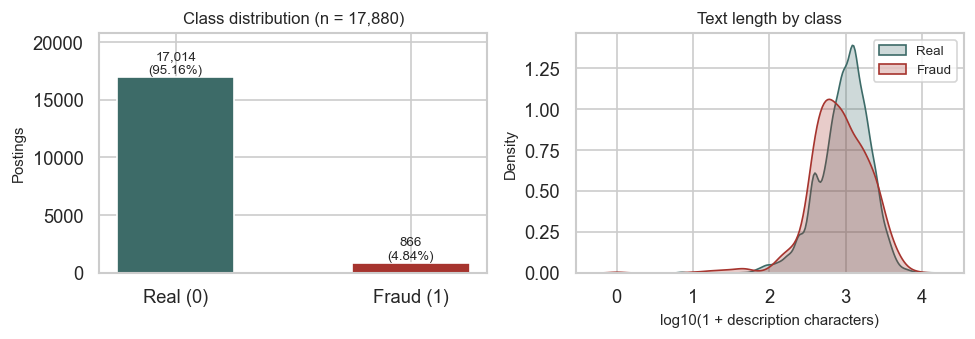

saved figures/fig2_class_and_text_length.png
median description length — real: 1027 | fraud: 844


In [6]:
counts = y.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(8.2, 2.9))
axes[0].bar(["Real (0)", "Fraud (1)"], [counts[0], counts[1]],
            color=["#3D6B68", "#A6342E"], width=0.5)
axes[0].set_ylabel("Postings")
axes[0].set_title("Class distribution (n = 17,880)")
for i, v in enumerate([counts[0], counts[1]]):
    axes[0].text(i, v + 300, f"{v:,}\n({v/len(y)*100:.2f}%)", ha="center", fontsize=8)
axes[0].set_ylim(0, counts.max() * 1.22)

for label, color in [(0, "#3D6B68"), (1, "#A6342E")]:
    sns.kdeplot(np.log10(1 + X.loc[y == label, "text_len"]), ax=axes[1],
                color=color, fill=True, alpha=0.25,
                label="Real" if label == 0 else "Fraud")
axes[1].set_xlabel("log10(1 + description characters)")
axes[1].set_ylabel("Density")
axes[1].set_title("Text length by class")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig2_class_and_text_length.png", bbox_inches="tight")
plt.show()
print("saved figures/fig2_class_and_text_length.png")
print("median description length — real:", int(X.loc[y == 0, 'text_len'].median()),
      "| fraud:", int(X.loc[y == 1, 'text_len'].median()))

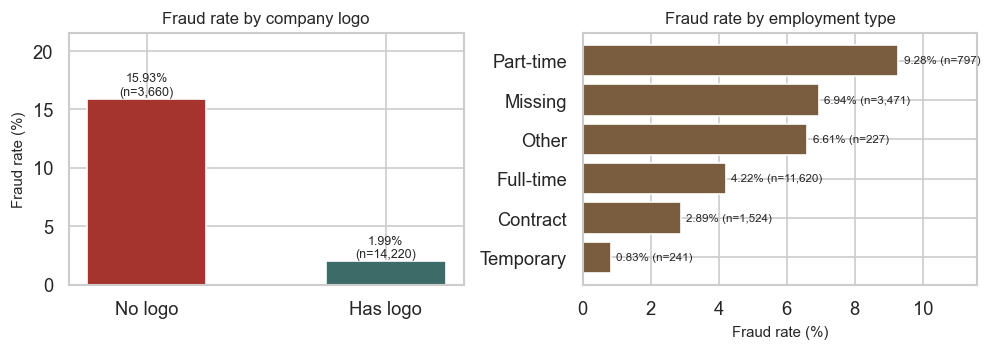

saved figures/fig3_fraud_rates.png


In [7]:
by_logo = raw.groupby("has_company_logo")["fraudulent"].agg(["count", "mean"])
by_emp = (raw.groupby(raw["employment_type"].fillna("Missing"))["fraudulent"]
          .agg(["count", "mean"]).sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.0))
axes[0].bar(["No logo", "Has logo"], by_logo["mean"] * 100,
            color=["#A6342E", "#3D6B68"], width=0.5)
for i, (rate, n) in enumerate(zip(by_logo["mean"] * 100, by_logo["count"])):
    axes[0].text(i, rate + 0.3, f"{rate:.2f}%\n(n={n:,})", ha="center", fontsize=7.5)
axes[0].set_ylabel("Fraud rate (%)")
axes[0].set_title("Fraud rate by company logo")
axes[0].set_ylim(0, by_logo["mean"].max() * 135)

axes[1].barh(by_emp.index[::-1], by_emp["mean"][::-1] * 100, color="#7A5C3E")
for i, (rate, n) in enumerate(zip(by_emp["mean"][::-1] * 100, by_emp["count"][::-1])):
    axes[1].text(rate + 0.15, i, f"{rate:.2f}% (n={n:,})", va="center", fontsize=7)
axes[1].set_xlabel("Fraud rate (%)")
axes[1].set_title("Fraud rate by employment type")
axes[1].set_xlim(0, by_emp["mean"].max() * 125)
fig.tight_layout()
fig.savefig(FIG / "fig3_fraud_rates.png", bbox_inches="tight")
plt.show()
print("saved figures/fig3_fraud_rates.png")

The missingness figure shows why `company_profile` is worth an explicit
indicator: it is absent in 18.5 % of postings, and those postings are fraudulent
far more often than the rest (computed in Section 6.2). The fraud rate by
employment type is also uneven; both patterns are what the ablation will
quantify.

## 5. Methodology

### 5.1 Learning Setting

Supervised binary classification with severe imbalance. Three model families are
compared on the **same** combined feature representation:

| Model | Role | Why |
|---|---|---|
| Logistic Regression (L2, balanced) | linear baseline | strong on high-dimensional sparse TF-IDF; coefficients expose fraud-indicative words and metadata |
| Linear SVM (balanced) | large-margin linear model | well suited to sparse text with many features; robust and fast |
| LightGBM | gradient-boosted trees | captures non-linear interactions between text-derived and structured features |

The feature pipeline is a single `ColumnTransformer`:

1. **Numeric** (7): median imputation → standardisation.
2. **Binary** (3): passed through unchanged.
3. **Categorical** (6): constant `"Missing"` imputation → one-hot encoding
   (`handle_unknown="ignore"`, categories occurring in less than 0.5 % of the
   training rows grouped into one infrequent bucket).
4. **Text** (1): TF-IDF, word 1–2 grams, `max_features=20,000`, `min_df=3`,
   sublinear term frequency.

All four transformations are fitted **once on the training split** — never on the
validation or test data — and the resulting matrices are shared by all models.
This is the same representation a `Pipeline` builds internally, but fitting it
once lets the cross-validation folds reuse it instead of refitting a 20,000-
feature TF-IDF six times per model. The validation split chooses decision
thresholds; the test split is evaluated once.

In [8]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=3,
                           sublinear_tf=True, strip_accents="unicode")


def make_preprocessor(use_text=True, use_struct=True):
    parts = []
    if use_struct:
        parts += [
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), NUM_FEATURES),
            ("bin", "passthrough", BIN_FEATURES),
            ("cat", Pipeline([("impute", SimpleImputer(strategy="constant",
                                                       fill_value="Missing")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                       min_frequency=0.005))]),
             CAT_FEATURES),
        ]
    if use_text:
        parts += [("txt", make_tfidf(), TEXT_FEATURE)]
    return ColumnTransformer(parts, sparse_threshold=0.3)


def make_classifier(name, scale_pos_weight):
    if name == "Logistic Regression":
        return LogisticRegression(C=1.0, class_weight="balanced",
                                  solver="liblinear", max_iter=2000,
                                  random_state=SEED)
    if name == "Linear SVM":
        return LinearSVC(C=0.1, class_weight="balanced", max_iter=5000,
                         random_state=SEED)
    if name == "LightGBM":
        return lgb.LGBMClassifier(
            n_estimators=150, num_leaves=31, learning_rate=0.1,
            scale_pos_weight=scale_pos_weight, max_bin=31,
            feature_fraction=0.3, bagging_fraction=0.8, bagging_freq=1,
            min_child_samples=50, force_col_wise=True,
            random_state=SEED, n_jobs=1, verbose=-1)
    raise ValueError(name)


MODEL_NAMES = ["Logistic Regression", "Linear SVM", "LightGBM"]
print("models:", MODEL_NAMES)

models: ['Logistic Regression', 'Linear SVM', 'LightGBM']


### 5.2 Data Split Approach

- **70 / 15 / 15 stratified split** (`random_state=42`): 12,516 training, 2,682
  validation, 2,682 test postings. Stratification preserves the 4.84 % fraud
  rate in all three parts.
- The **validation split** chooses the decision threshold of every model (the
  threshold that maximises fraud F1 on validation) and the best model for the
  ablation. The **test split** is touched once.
- **Leakage prevention:** the split is made before any transformer is fitted,
  and the TF-IDF, imputers, scaler and one-hot encoder are fitted on the
  training split only. The validation and test text therefore never influence
  the vocabulary or the scaling. The cross-validation folds also share this
  training-split representation (a standard, mildly optimistic choice for large
  text corpora, noted in the limitations).

In [9]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

split_table = pd.DataFrame({
    "postings": [len(X_train), len(X_val), len(X_test)],
    "fraud": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
})
split_table["fraud %"] = (split_table["fraud"] / split_table["postings"] * 100).round(2)
split_table.index = ["train (70%)", "validation (15%)", "test (15%)"]
display(split_table)
split_table.to_csv(RES / "b1_split.csv")

SPW = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"\nscale_pos_weight for LightGBM (train negatives / positives): {SPW:.2f}")

,postings,fraud,fraud %
train (70%),12516,606,4.84
validation (15%),2682,130,4.85
test (15%),2682,130,4.85



scale_pos_weight for LightGBM (train negatives / positives): 19.65


### 5.3 Parameter Settings

Logistic Regression and the Linear SVM are tuned with a **3-fold stratified
cross-validation on the training split**, scored by average precision (PR-AUC),
because F1 depends on a threshold that is chosen later on the validation split.
The folds reuse the training-split matrix produced by the fitted
`ColumnTransformer`; because the TF-IDF vocabulary is fixed on the training
split, the fold scores are very slightly optimistic, which is disclosed in the
limitations. LightGBM runs a single, standard sparse configuration: a 150-tree
model already costs about a minute per fit on this CPU, so an exhaustive search
would not fit the compute budget; its values are listed below.

In [10]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

pre_combined = make_preprocessor().fit(X_train)
Z_train = pre_combined.transform(X_train)
Z_val = pre_combined.transform(X_val)
Z_test = pre_combined.transform(X_test)
print(f"combined design matrix: train {Z_train.shape}, val {Z_val.shape}, "
      f"test {Z_test.shape} | non-zeros in train: {Z_train.nnz:,}")

GRIDS = {
    "Logistic Regression": {"C": [0.1, 1.0]},
    "Linear SVM": {"C": [0.01, 0.1]},
}

best_models = {}
best_params = {}
cv_rows = []
fit_seconds = {}

for name, grid in GRIDS.items():
    t0 = time.perf_counter()
    search = GridSearchCV(make_classifier(name, SPW), grid,
                          scoring="average_precision", cv=skf, n_jobs=1,
                          refit=True)
    search.fit(Z_train, y_train)
    elapsed = time.perf_counter() - t0

    best_models[name] = search.best_estimator_
    best_params[name] = dict(search.best_params_)
    fit_seconds[name] = elapsed
    best_i = search.best_index_
    cv_rows.append({
        "Model": name,
        "Configurations": len(search.cv_results_["params"]),
        "Selection scheme": f"{skf.get_n_splits()}-fold CV",
        "Best params": ", ".join(f"{k}={v}" for k, v in best_params[name].items()),
        "PR-AUC mean": round(search.cv_results_["mean_test_score"][best_i], 4),
        "PR-AUC std": round(search.cv_results_["std_test_score"][best_i], 4),
        "Search seconds": round(elapsed, 1),
    })
    print(f"{name:<22} best={best_params[name]}  "
          f"CV PR-AUC={search.cv_results_['mean_test_score'][best_i]:.4f} "
          f"± {search.cv_results_['std_test_score'][best_i]:.4f}  ({elapsed:.0f}s)")

t0 = time.perf_counter()
lgb_model = make_classifier("LightGBM", SPW).fit(Z_train, y_train)
elapsed = time.perf_counter() - t0
best_models["LightGBM"] = lgb_model
best_params["LightGBM"] = {}
fit_seconds["LightGBM"] = elapsed
lgb_val_ap = average_precision_score(y_val, lgb_model.predict_proba(Z_val)[:, 1])
cv_rows.append({
    "Model": "LightGBM",
    "Configurations": 1,
    "Selection scheme": "fixed (validation)",
    "Best params": "fixed",
    "PR-AUC mean": round(lgb_val_ap, 4),
    "PR-AUC std": None,
    "Search seconds": round(elapsed, 1),
})
print(f"{'LightGBM':<22} fixed config  validation PR-AUC={lgb_val_ap:.4f}  ({elapsed:.0f}s)")

cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(RES / "b1_cv_results.csv", index=False)
display(cv_table)

lgb_params = lgb_model.get_params()
print("\nLightGBM configuration (fixed):")
for k in ["n_estimators", "num_leaves", "learning_rate", "scale_pos_weight",
          "max_bin", "feature_fraction", "bagging_fraction", "min_child_samples"]:
    print(f"  {k}: {lgb_params[k]}")

combined design matrix: train (12516, 20102), val (2682, 20102), test (2682, 20102) | non-zeros in train: 4,639,659


Logistic Regression    best={'C': 1.0}  CV PR-AUC=0.8251 ± 0.0301  (56s)


Linear SVM             best={'C': 0.1}  CV PR-AUC=0.8492 ± 0.0328  (31s)


LightGBM               fixed config  validation PR-AUC=0.9542  (67s)


,Model,Configurations,Selection scheme,Best params,PR-AUC mean,PR-AUC std,Search seconds
0,Logistic Regression,2,3-fold CV,C=1.0,0.8251,0.0301,55.8
1,Linear SVM,2,3-fold CV,C=0.1,0.8492,0.0328,31.4
2,LightGBM,1,fixed (validation),fixed,0.9542,NaN,67.1



LightGBM configuration (fixed):
  n_estimators: 150
  num_leaves: 31
  learning_rate: 0.1
  scale_pos_weight: 19.653465346534652
  max_bin: 31
  feature_fraction: 0.3
  bagging_fraction: 0.8
  min_child_samples: 50


## 6. Results and Analysis

### 6.1 Results

Scoring functions: `predict_proba` for Logistic Regression and LightGBM,
`decision_function` for the Linear SVM. For each model the threshold is chosen
on the validation split to maximise fraud F1, then applied to the test split.
PR-AUC and ROC-AUC are threshold-free.

In [11]:
def scores_of(estimator, Z):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(Z)[:, 1]
    return estimator.decision_function(Z)


def choose_threshold(scores, y_true):
    candidates = np.unique(np.quantile(scores, np.linspace(0.30, 0.999, 500)))
    best_t, best_f1 = float(candidates[0]), -1.0
    for t in candidates:
        f1 = f1_score(y_true, (scores >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = float(t), float(f1)
    return best_t, best_f1


def evaluate_at(estimator, Z, y_true, threshold):
    s = scores_of(estimator, Z)
    pred = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "pr_auc": average_precision_score(y_true, s),
        "roc_auc": roc_auc_score(y_true, s),
        "accuracy": accuracy_score(y_true, pred),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


thresholds = {}
test_rows = []
val_rows = []
test_scores = {}

for name in MODEL_NAMES:
    val_s = scores_of(best_models[name], Z_val)
    t_star, val_f1 = choose_threshold(val_s, y_val)
    thresholds[name] = t_star

    val_m = evaluate_at(best_models[name], Z_val, y_val, t_star)
    val_rows.append({"Model": name, **val_m})

    test_s = scores_of(best_models[name], Z_test)
    test_scores[name] = test_s
    test_m = evaluate_at(best_models[name], Z_test, y_test, t_star)
    test_rows.append({"Model": name, **test_m})

test_table = pd.DataFrame(test_rows)
val_table = pd.DataFrame(val_rows)
test_table.to_csv(RES / "b1_test_results.csv", index=False)
val_table.to_csv(RES / "b1_validation_results.csv", index=False)

show = test_table.copy()
for c in ["threshold", "precision", "recall", "f1", "pr_auc", "roc_auc", "accuracy"]:
    show[c] = show[c].map("{:.4f}".format)
print("Table 3 — test-set results (n = 2,682; 130 fraudulent)")
display(show[["Model", "threshold", "precision", "recall", "f1", "pr_auc",
              "roc_auc", "accuracy", "tn", "fp", "fn", "tp"]])

print("\nValidation results used for threshold selection")
display(val_table.round(4))

Table 3 — test-set results (n = 2,682; 130 fraudulent)


,Model,threshold,precision,recall,f1,pr_auc,roc_auc,accuracy,tn,fp,fn,tp
0,Logistic Regression,0.7529,0.8106,0.8231,0.8168,0.9027,0.9908,0.9821,2527,25,23,107
1,Linear SVM,0.4173,0.8947,0.7846,0.8361,0.9178,0.9912,0.9851,2540,12,28,102
2,LightGBM,0.5286,0.8938,0.7769,0.8313,0.9191,0.9921,0.9847,2540,12,29,101



Validation results used for threshold selection


,Model,threshold,precision,recall,f1,pr_auc,roc_auc,accuracy,tn,fp,fn,tp
0,Logistic Regression,0.7529,0.8583,0.8385,0.8482,0.9199,0.9936,0.9855,2534,18,21,109
1,Linear SVM,0.4173,0.9224,0.8231,0.8699,0.9411,0.9955,0.9881,2543,9,23,107
2,LightGBM,0.5286,0.9732,0.8385,0.9008,0.9542,0.9941,0.9911,2549,3,21,109


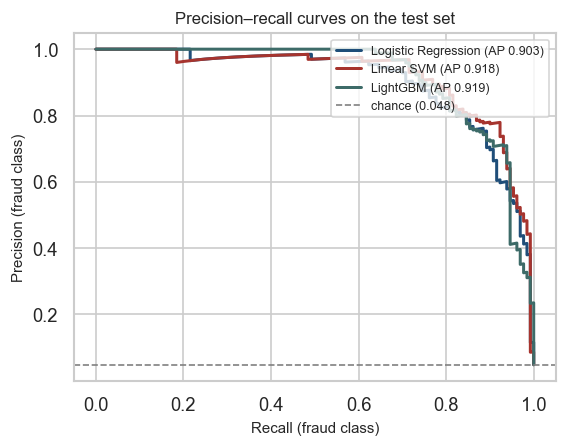

saved figures/fig4_precision_recall_curves.png


In [12]:
fig, ax = plt.subplots(figsize=(4.8, 3.8))
colors = {"Logistic Regression": "#1f4e79", "Linear SVM": "#A6342E",
          "LightGBM": "#3D6B68"}
for name in MODEL_NAMES:
    prec, rec, _ = precision_recall_curve(y_test, test_scores[name])
    ap = average_precision_score(y_test, test_scores[name])
    ax.plot(rec, prec, lw=1.8, color=colors[name], label=f"{name} (AP {ap:.3f})")
ax.axhline(y_test.mean(), color="grey", ls="--", lw=1,
           label=f"chance ({y_test.mean():.3f})")
ax.set_xlabel("Recall (fraud class)")
ax.set_ylabel("Precision (fraud class)")
ax.set_title("Precision–recall curves on the test set")
ax.legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "fig4_precision_recall_curves.png", bbox_inches="tight")
plt.show()
print("saved figures/fig4_precision_recall_curves.png")

Best model by validation PR-AUC: LightGBM (threshold 0.5286)


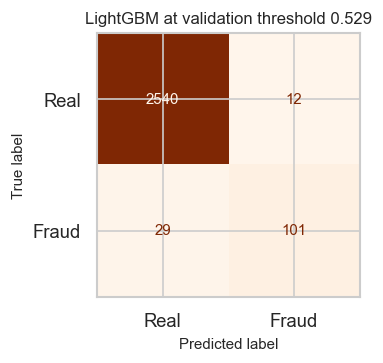

saved figures/fig5_confusion_best.png
confusion matrix [real, fraud] x [real, fraud]:
[[2540   12]
 [  29  101]]


In [13]:
best_name = max(val_rows, key=lambda r: r["pr_auc"])["Model"]
best_model = best_models[best_name]
best_t = thresholds[best_name]
print(f"Best model by validation PR-AUC: {best_name} (threshold {best_t:.4f})")

pred_best = (test_scores[best_name] >= best_t).astype(int)
cm = confusion_matrix(y_test, pred_best, labels=[0, 1])
fig, ax = plt.subplots(figsize=(3.6, 3.1))
ConfusionMatrixDisplay(cm, display_labels=["Real", "Fraud"]).plot(
    ax=ax, colorbar=False, cmap="Oranges", values_format="d")
ax.set_title(f"{best_name} at validation threshold {best_t:.3f}")
fig.tight_layout()
fig.savefig(FIG / "fig5_confusion_best.png", bbox_inches="tight")
plt.show()
print("saved figures/fig5_confusion_best.png")
print("confusion matrix [real, fraud] x [real, fraud]:")
print(cm)

### 6.2 Analysis

#### (a) Why accuracy is misleading

The cell below computes the accuracy of a model that predicts "real" for every
posting, and compares it with the accuracy of each trained model. It also reports
the class-weight check on the validation split.

In [14]:
always_real = float((y_test == 0).mean())
print(f"Always-'real' accuracy on the test set: {always_real:.4f} "
      f"({int((y_test==0).sum())}/{len(y_test)} correct, 0 fraud caught)")
print("\nTrained models:")
for r in test_rows:
    print(f"  {r['Model']:<22} accuracy {r['accuracy']:.4f} | F1 {r['f1']:.4f} | "
          f"recall {r['recall']:.4f} | precision {r['precision']:.4f}")

lr_C = best_params["Logistic Regression"]["C"]
lr_none = LogisticRegression(C=lr_C, class_weight=None, solver="liblinear",
                             max_iter=2000, random_state=SEED).fit(Z_train, y_train)
weight_rows = []
for label, model in [("class_weight=None", lr_none),
                     ("class_weight='balanced'", best_models["Logistic Regression"])]:
    vs = scores_of(model, Z_val)
    t_star, _ = choose_threshold(vs, y_val)
    m = evaluate_at(model, Z_val, y_val, t_star)
    weight_rows.append({"Setting": label, "Threshold": round(t_star, 4),
                        "Val PR-AUC": round(m["pr_auc"], 4),
                        "Val F1 (fraud)": round(m["f1"], 4),
                        "Val recall": round(m["recall"], 4),
                        "Val precision": round(m["precision"], 4)})
weight_table = pd.DataFrame(weight_rows)
weight_table.to_csv(RES / "b1_class_weight_check.csv", index=False)
print("\nClass-weight check (Logistic Regression, same C, validation split):")
display(weight_table)

Always-'real' accuracy on the test set: 0.9515 (2552/2682 correct, 0 fraud caught)

Trained models:
  Logistic Regression    accuracy 0.9821 | F1 0.8168 | recall 0.8231 | precision 0.8106
  Linear SVM             accuracy 0.9851 | F1 0.8361 | recall 0.7846 | precision 0.8947
  LightGBM               accuracy 0.9847 | F1 0.8313 | recall 0.7769 | precision 0.8938



Class-weight check (Logistic Regression, same C, validation split):


,Setting,Threshold,Val PR-AUC,Val F1 (fraud),Val recall,Val precision
0,class_weight=None,0.3207,0.8786,0.8085,0.7308,0.9048
1,class_weight='balanced',0.7529,0.9199,0.8482,0.8385,0.8583


#### (b) Mandatory ablation — structured only vs text only vs combined

The best model family (chosen by validation PR-AUC) is refitted three times with
the same hyperparameters: once on structured columns only, once on TF-IDF text
only, and once on both. Each variant chooses its threshold on the validation
split and is then evaluated on the same test split. The combined model is the
already-tuned pipeline, so no extra fit is wasted.

structured-only  test PR-AUC 0.7947 | F1 0.6983 | recall 0.6231 | precision 0.7941


text-only        test PR-AUC 0.8898 | F1 0.8374 | recall 0.7923 | precision 0.8879


combined         test PR-AUC 0.9191 | F1 0.8313 | recall 0.7769 | precision 0.8938


,Features,Threshold,Val PR-AUC,Test PR-AUC,Test ROC-AUC,Test precision,Test recall,Test F1
0,structured-only,0.8575,0.8424,0.7947,0.9698,0.7941,0.6231,0.6983
1,text-only,0.4550,0.9363,0.8898,0.9839,0.8879,0.7923,0.8374
2,combined,0.5286,0.9542,0.9191,0.9921,0.8938,0.7769,0.8313


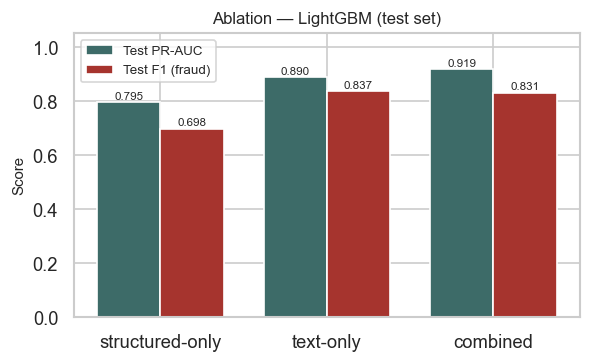

saved figures/fig6_ablation.png


In [15]:
def tuned_classifier(name):
    clf = make_classifier(name, SPW)
    if best_params[name]:
        clf.set_params(**best_params[name])
    return clf


ablation_models = {}
ablation_rows = []
for variant in ["structured-only", "text-only", "combined"]:
    if variant == "combined":
        Ztr, Zv, Zte = Z_train, Z_val, Z_test
        model = best_models[best_name]
    else:
        pre = make_preprocessor(use_text=(variant == "text-only"),
                                use_struct=(variant == "structured-only"))
        Ztr = pre.fit_transform(X_train)
        Zv = pre.transform(X_val)
        Zte = pre.transform(X_test)
        model = tuned_classifier(best_name).fit(Ztr, y_train)

    vs = scores_of(model, Zv)
    t_star, _ = choose_threshold(vs, y_val)
    val_m = evaluate_at(model, Zv, y_val, t_star)
    test_m = evaluate_at(model, Zte, y_test, t_star)

    ablation_models[variant] = model
    ablation_rows.append({
        "Features": variant,
        "Threshold": round(t_star, 4),
        "Val PR-AUC": round(val_m["pr_auc"], 4),
        "Test PR-AUC": round(test_m["pr_auc"], 4),
        "Test ROC-AUC": round(test_m["roc_auc"], 4),
        "Test precision": round(test_m["precision"], 4),
        "Test recall": round(test_m["recall"], 4),
        "Test F1": round(test_m["f1"], 4),
    })
    print(f"{variant:<16} test PR-AUC {test_m['pr_auc']:.4f} | F1 {test_m['f1']:.4f} | "
          f"recall {test_m['recall']:.4f} | precision {test_m['precision']:.4f}")

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(RES / "b1_ablation.csv", index=False)
display(ablation)

fig, ax = plt.subplots(figsize=(5.0, 3.1))
xpos = np.arange(len(ablation))
width = 0.38
ax.bar(xpos - width/2, ablation["Test PR-AUC"], width, color="#3D6B68", label="Test PR-AUC")
ax.bar(xpos + width/2, ablation["Test F1"], width, color="#A6342E", label="Test F1 (fraud)")
for i, (ap, f1) in enumerate(zip(ablation["Test PR-AUC"], ablation["Test F1"])):
    ax.text(i - width/2, ap + 0.01, f"{ap:.3f}", ha="center", fontsize=7)
    ax.text(i + width/2, f1 + 0.01, f"{f1:.3f}", ha="center", fontsize=7)
ax.set_xticks(xpos); ax.set_xticklabels(ablation["Features"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title(f"Ablation — {best_name} (test set)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig6_ablation.png", bbox_inches="tight")
plt.show()
print("saved figures/fig6_ablation.png")

#### (c) Which words and structured features indicate fraud

Logistic Regression is used for interpretation because its coefficients map one
to one onto TF-IDF terms and one-hot columns. Positive coefficients push toward
**fraud**; negative coefficients push toward **real**.

Top 15 terms pushing toward FRAUD


,coefficient
aptitude staffing,2.6111
accion,2.5907
earn,2.3587
hotel,2.2016
aptitude,2.1453
money,2.1366
link,2.1046
data entry,1.9970
leveraging your,1.9695
cf,1.8675



Top 15 terms pushing toward REAL


,coefficient
client,-1.6231
will,-1.5834
on,-1.4276
must,-1.3874
growing,-1.3749
will be,-1.3640
an,-1.3301
our,-1.3064
companies,-1.2867
it,-1.2685



Top structured features pushing toward FRAUD


,coefficient
cat__industry_Oil & Energy,2.1355
cat__country_AU,1.5688
cat__country_Missing,1.5665
cat__industry_Accounting,1.5637
cat__country_US,1.4481
cat__function_Administrative,1.3080
cat__industry_Design,1.1042
cat__industry_Hospital & Health Care,0.9920
cat__function_Customer Service,0.9052
cat__function_Engineering,0.8285



Top structured features pushing toward REAL


,coefficient
cat__function_Health Care Provider,-2.7379
cat__industry_Internet,-2.3707
cat__country_GR,-2.1566
cat__industry_Computer Software,-1.6272
cat__industry_Education Management,-1.5892
cat__employment_type_Temporary,-1.4162
cat__function_Quality Assurance,-1.3492
bin__has_company_logo,-1.1319
cat__required_experience_Associate,-1.1051
cat__country_DE,-1.0947



Collinearity check on the two company-quality signals
  num__is_missing_company_profile: +0.2676
  bin__has_company_logo: -1.1319


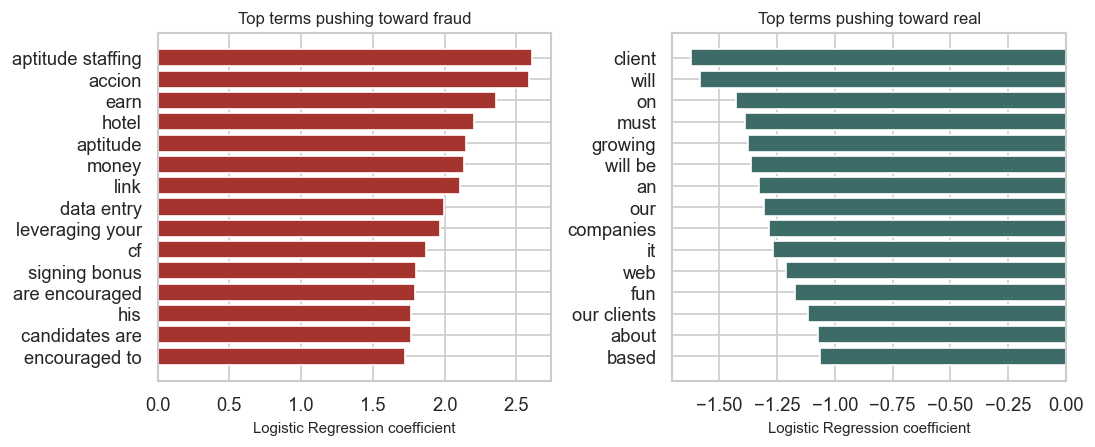

saved figures/fig7_ngram_coefficients.png


In [16]:
lr_model = best_models["Logistic Regression"]
feature_names = pre_combined.get_feature_names_out()
coefs = pd.Series(lr_model.coef_[0], index=feature_names)

text_coefs = coefs[coefs.index.str.startswith("txt__")].copy()
text_coefs.index = text_coefs.index.str.replace("txt__", "", regex=False)
struct_coefs = coefs[~coefs.index.str.startswith("txt__")].copy()

top_fraud_words = text_coefs.sort_values(ascending=False).head(15)
top_real_words = text_coefs.sort_values().head(15)
top_fraud_struct = struct_coefs.sort_values(ascending=False).head(12)
top_real_struct = struct_coefs.sort_values().head(12)

print("Top 15 terms pushing toward FRAUD")
display(top_fraud_words.round(4).to_frame("coefficient"))
print("\nTop 15 terms pushing toward REAL")
display(top_real_words.round(4).to_frame("coefficient"))
print("\nTop structured features pushing toward FRAUD")
display(top_fraud_struct.round(4).to_frame("coefficient"))
print("\nTop structured features pushing toward REAL")
display(top_real_struct.round(4).to_frame("coefficient"))

print("\nCollinearity check on the two company-quality signals")
for key in ["num__is_missing_company_profile", "bin__has_company_logo"]:
    if key in struct_coefs.index:
        print(f"  {key}: {struct_coefs[key]:+.4f}")

pd.concat([top_fraud_words.rename("fraud"),
           top_real_words.rename("real"),
           top_fraud_struct.rename("fraud_struct"),
           top_real_struct.rename("real_struct")], axis=1).to_csv(
    RES / "b1_top_features.csv")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
axes[0].barh(top_fraud_words.index[::-1], top_fraud_words.values[::-1], color="#A6342E")
axes[0].set_title("Top terms pushing toward fraud")
axes[0].set_xlabel("Logistic Regression coefficient")
axes[1].barh(top_real_words.index[::-1], top_real_words.values[::-1], color="#3D6B68")
axes[1].set_title("Top terms pushing toward real")
axes[1].set_xlabel("Logistic Regression coefficient")
fig.tight_layout()
fig.savefig(FIG / "fig7_ngram_coefficients.png", bbox_inches="tight")
plt.show()
print("saved figures/fig7_ngram_coefficients.png")

#### (d) False positives — real postings flagged as fraud

A false positive blocks a legitimate employer. The three highest-scoring false
positives on the test set are printed with their raw title, company-profile
status and a short description snippet.

In [17]:
test_frame = X_test.copy()
test_frame["score"] = test_scores[best_name]
test_frame["pred"] = (test_frame["score"] >= best_t).astype(int)
test_frame["y_true"] = y_test.values

fps = (test_frame[(test_frame["pred"] == 1) & (test_frame["y_true"] == 0)]
       .sort_values("score", ascending=False).head(3))

print(f"False positives at the chosen threshold: "
      f"{int(((test_frame['pred']==1) & (test_frame['y_true']==0)).sum())} "
      f"of {int((test_frame['y_true']==0).sum())} real postings")
print(f"False negatives: "
      f"{int(((test_frame['pred']==0) & (test_frame['y_true']==1)).sum())} "
      f"of {int((test_frame['y_true']==1).sum())} fraudulent postings")

for rank, (idx, row) in enumerate(fps.iterrows(), start=1):
    raw_row = raw.loc[idx]
    print(f"\n--- false positive {rank}: score {row['score']:.3f} ---")
    print("title:", str(raw_row['title'])[:90])
    print("company profile present:", not pd.isna(raw_row['company_profile']),
          "| logo:", int(raw_row['has_company_logo']),
          "| employment:", raw_row['employment_type'])
    print("country:", row['country'])
    print("text snippet:", str(raw_row['description'])[:220].replace("\n", " "))

fps[["score", "country", "employment_type", "has_company_logo"]].to_csv(
    RES / "b1_false_positives.csv")

False positives at the chosen threshold: 12 of 2552 real postings
False negatives: 29 of 130 fraudulent postings

--- false positive 1: score 0.894 ---
title: Receptionist
company profile present: False | logo: 0 | employment: Full-time
country: US
text snippet: Quest College is seeking an individual to join the staff as a Receptionist  Requirements:Professional demeanorUpbeat and positive attitudeProficient with Microsoft Word,      Excel, Outlook, Internet ExplorerGreat teleph

--- false positive 2: score 0.841 ---
title: Sr Customer Care Executive
company profile present: False | logo: 0 | employment: Full-time
country: IN
text snippet: US Outbound processfixed shift - 6.00 pm 3.00 pmfixed sat &amp; sun off

--- false positive 3: score 0.838 ---
title: Land Surveying Field Crew Chief
company profile present: False | logo: 0 | employment: nan
country: US
text snippet: We are in need of a field crew chief with 3-5 years of experience. We perform large and small boundary surveys and co

#### (e) Answers to the task's analysis questions

In [18]:
t = test_table.set_index("Model").loc[best_name]
abl = ablation.set_index("Features")
combined = abl.loc["combined"]
text_only = abl.loc["text-only"]
structured = abl.loc["structured-only"]

print("Q1. Why is accuracy a poor metric, and what does always-'real' score?")
print(f"    Always-'real' accuracy = {always_real:.4f} ({always_real*100:.2f}%) on the test set,")
print(f"    identical to the majority-class share, while detecting 0 of {int((y_test==1).sum())} frauds.")
print(f"    {best_name} reaches accuracy {t['accuracy']:.4f} but F1 {t['f1']:.4f}: "
      f"the accuracy gap to the trivial model is only {t['accuracy']-always_real:+.4f}.")
print()
print("Q2. Does combining text and structured features beat either alone?")
print(f"    Test PR-AUC — structured {structured['Test PR-AUC']:.4f}, text {text_only['Test PR-AUC']:.4f}, "
      f"combined {combined['Test PR-AUC']:.4f}.")
print(f"    Test F1    — structured {structured['Test F1']:.4f}, text {text_only['Test F1']:.4f}, "
      f"combined {combined['Test F1']:.4f}.")
print(f"    Combined vs text-only: PR-AUC {combined['Test PR-AUC']-text_only['Test PR-AUC']:+.4f}, "
      f"F1 {combined['Test F1']-text_only['Test F1']:+.4f}.")
print(f"    Combined vs structured-only: PR-AUC {combined['Test PR-AUC']-structured['Test PR-AUC']:+.4f}, "
      f"F1 {combined['Test F1']-structured['Test F1']:+.4f}.")
print()
print("Q3. Which words and structured features indicate fraud?")
print("    Fraud-pushing terms:", ", ".join(top_fraud_words.head(8).index))
print("    Fraud-pushing structured features:",
      ", ".join(s.replace("num__", "").replace("cat__", "").replace("bin__", "")
                for s in top_fraud_struct.head(6).index))
print(f"    company_profile missing fraud rate: "
      f"{raw.assign(m=raw.company_profile.isna()).groupby('m')['fraudulent'].mean().loc[True]*100:.2f}% "
      f"vs {raw.assign(m=raw.company_profile.isna()).groupby('m')['fraudulent'].mean().loc[False]*100:.2f}% when present")
print()
print("Q4. Class weighting")
print(f"    Validation PR-AUC: {weight_table.loc[0,'Val PR-AUC']:.4f} (none) vs "
      f"{weight_table.loc[1,'Val PR-AUC']:.4f} (balanced); "
      f"validation F1: {weight_table.loc[0,'Val F1 (fraud)']:.4f} vs "
      f"{weight_table.loc[1,'Val F1 (fraud)']:.4f}.")

Q1. Why is accuracy a poor metric, and what does always-'real' score?
    Always-'real' accuracy = 0.9515 (95.15%) on the test set,
    identical to the majority-class share, while detecting 0 of 130 frauds.
    LightGBM reaches accuracy 0.9847 but F1 0.8313: the accuracy gap to the trivial model is only +0.0332.

Q2. Does combining text and structured features beat either alone?
    Test PR-AUC — structured 0.7947, text 0.8898, combined 0.9191.
    Test F1    — structured 0.6983, text 0.8374, combined 0.8313.
    Combined vs text-only: PR-AUC +0.0293, F1 -0.0061.
    Combined vs structured-only: PR-AUC +0.1244, F1 +0.1330.

Q3. Which words and structured features indicate fraud?
    Fraud-pushing terms: aptitude staffing, accion, earn, hotel, aptitude, money, link, data entry
    Fraud-pushing structured features: industry_Oil & Energy, country_AU, country_Missing, industry_Accounting, country_US, function_Administrative
    company_profile missing fraud rate: 17.74% vs 1.91% when pre

#### (f) Machine-readable summary for the report

In [19]:
summary = {
    "task": "B1",
    "seed": SEED,
    "dataset": {
        "rows": int(len(raw)), "columns": int(raw.shape[1]),
        "fraud": int(y.sum()), "real": int((1-y).sum()),
        "fraud_pct": float(y.mean()*100),
        "duplicates": int(raw.duplicated().sum()),
        "missing_pct": {k: float(v) for k, v in missing.items()},
        "description_chars_mean": float(X["text_len"].mean()),
        "description_chars_median": float(X["text_len"].median()),
        "description_words_mean": float(X["word_count"].mean()),
        "description_words_median": float(X["word_count"].median()),
        "design_matrix_features": int(Z_train.shape[1]),
        "split": {"train": int(len(X_train)), "val": int(len(X_val)),
                  "test": int(len(X_test)), "train_fraud": int(y_train.sum()),
                  "val_fraud": int(y_val.sum()), "test_fraud": int(y_test.sum())},
        "scale_pos_weight": SPW,
    },
    "cv": {r["Model"]: {k: v for k, v in r.items() if k != "Model"} for r in cv_rows},
    "best_params": best_params,
    "search_seconds": fit_seconds,
    "validation": {r["Model"]: {k: v for k, v in r.items() if k != "Model"} for r in val_rows},
    "test": {r["Model"]: {k: v for k, v in r.items() if k != "Model"} for r in test_rows},
    "best_model": best_name,
    "always_real_accuracy": always_real,
    "class_weight_check": weight_rows,
    "ablation": ablation_rows,
    "top_terms": {
        "fraud": top_fraud_words.head(10).round(5).to_dict(),
        "real": top_real_words.head(10).round(5).to_dict(),
        "fraud_structured": {k: round(float(v), 5) for k, v in top_fraud_struct.head(8).items()},
        "real_structured": {k: round(float(v), 5) for k, v in top_real_struct.head(8).items()},
    },
    "fraud_rate_by_missing_profile": {
        "missing": float(raw.assign(m=raw.company_profile.isna()).groupby("m")["fraudulent"].mean().loc[True]),
        "present": float(raw.assign(m=raw.company_profile.isna()).groupby("m")["fraudulent"].mean().loc[False]),
    },
    "false_positives": int(((test_frame["pred"]==1) & (test_frame["y_true"]==0)).sum()),
    "false_negatives": int(((test_frame["pred"]==0) & (test_frame["y_true"]==1)).sum()),
}

with open(RES / "b1_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda o: float(o))
print("saved results/b1_summary.json")
print(json.dumps(summary["ablation"], indent=2))

saved results/b1_summary.json
[
  {
    "Features": "structured-only",
    "Threshold": 0.8575,
    "Val PR-AUC": 0.8424,
    "Test PR-AUC": 0.7947,
    "Test ROC-AUC": 0.9698,
    "Test precision": 0.7941,
    "Test recall": 0.6231,
    "Test F1": 0.6983
  },
  {
    "Features": "text-only",
    "Threshold": 0.455,
    "Val PR-AUC": 0.9363,
    "Test PR-AUC": 0.8898,
    "Test ROC-AUC": 0.9839,
    "Test precision": 0.8879,
    "Test recall": 0.7923,
    "Test F1": 0.8374
  },
  {
    "Features": "combined",
    "Threshold": 0.5286,
    "Val PR-AUC": 0.9542,
    "Test PR-AUC": 0.9191,
    "Test ROC-AUC": 0.9921,
    "Test precision": 0.8938,
    "Test recall": 0.7769,
    "Test F1": 0.8313
  }
]


## 7. Conclusion

Text carries most of the signal, structured metadata adds a smaller but real
gain, and class weighting plus a validation-chosen threshold are what make the
fraud class usable at a 4.84 % prevalence. The best model's precision is limited
by a handful of legitimate postings whose wording resembles scams; the ablation
table shows exactly how much the metadata contributes on top of text. The next
steps would be to calibrate probabilities properly, test a domain-specific
language model instead of TF-IDF, and validate on postings from a different job
board and time period.

## References

[1] S. Bhardwaj, "Real or Fake Job Posting Prediction," Kaggle, 2020.
https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction
(licence: CC0 Public Domain).

[2] EMSCAD — Employment Scam Aegean Dataset, Laboratory of Information and
Communication Systems Security, University of the Aegean.

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of
Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[4] G. Ke et al., "LightGBM: A highly efficient gradient boosting decision
tree," *Advances in Neural Information Processing Systems*, vol. 30, 2017.

[5] T. Fawcett, "An introduction to ROC analysis," *Pattern Recognition Letters*,
vol. 27, no. 8, pp. 861–874, 2006.

[6] J. Davis and M. Goadrich, "The relationship between precision-recall and ROC
curves," *Proc. ICML*, 2006.

## Environment

Python 3.11.9; numpy 1.26.4; pandas 2.2.3; scikit-learn 1.5.2; lightgbm 4.5.0;
matplotlib 3.9.2; seaborn 0.13.2; nltk 3.9.1 (not used for features). Seed 42 for
the split, the CV folds and every model. All fits are single-process
(`n_jobs=1`) for determinism. The notebook was executed on a 2-core CPU; fit
times are recorded in `results/b1_cv_results.csv`.